# 03 - Fitur Harga (K1) dan Indikator Teknikal (K2)

Semua fitur dihitung **di dalam masing-masing segmen** sehingga perhitungan indikator dimulai ulang setelah *gap* tak terjelaskan.

- **K1 (9 fitur harga):** `return_lag_0` s.d. `return_lag_5`, `log_close_open`, `log_high_low`, `sigma_24`
- **K2 (K1 + 4 fitur teknikal):** `rsi_14` (penghalusan Wilder), `macd_line_norm`, `macd_signal_norm`, `macd_hist_norm` (MACD 12, 26, 9 dibagi `close`)
- **Pemanasan (*warm-up*):** observasi mulai dipakai pada **bar ke-51** di setiap segmen (minimal 50 bar valid sebelumnya).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "../data/interim/phase4-p0"
RSI_PERIOD = 14
MACD_FAST = 12
MACD_SLOW = 26
MACD_SIGNAL = 9
BAR_AWAL_PAKAI = 51

K1 = [
    "return_lag_0", "return_lag_1", "return_lag_2",
    "return_lag_3", "return_lag_4", "return_lag_5",
    "log_close_open", "log_high_low", "sigma_24",
]
TEKNIKAL = ["rsi_14", "macd_line_norm", "macd_signal_norm", "macd_hist_norm"]
K2 = K1 + TEKNIKAL

## 1. Fungsi RSI 14 (Penghalusan Wilder)

- Perubahan harga $d_t = C_t - C_{t-1}$, kenaikan $g_t = \max(d_t, 0)$, penurunan $\ell_t = \max(-d_t, 0)$.
- Nilai awal = rata-rata 14 perubahan pertama, selanjutnya dihaluskan dengan rumus Wilder.

In [2]:
def hitung_rsi_wilder(close, n=14):
    hasil = np.full(len(close), np.nan)
    if len(close) <= n:
        return hasil

    beda = np.diff(close)
    naik = np.maximum(beda, 0)
    turun = np.maximum(-beda, 0)

    g = naik[:n].mean()
    l = turun[:n].mean()

    def rumus_rsi(avg_gain, avg_loss):
        if avg_gain == 0 and avg_loss == 0:
            return 50.0
        if avg_loss == 0:
            return 100.0
        return 100.0 - 100.0 / (1.0 + avg_gain / avg_loss)

    hasil[n] = rumus_rsi(g, l)
    for i in range(n + 1, len(close)):
        g = ((n - 1) * g + naik[i - 1]) / n
        l = ((n - 1) * l + turun[i - 1]) / n
        hasil[i] = rumus_rsi(g, l)

    return hasil

## 2. Fungsi EMA dan MACD (12, 26, 9)

In [3]:
def hitung_ema(nilai, p):
    hasil = np.full(len(nilai), np.nan)
    if len(nilai) < p:
        return hasil

    hasil[p - 1] = nilai[:p].mean()
    alpha = 2 / (p + 1)
    for i in range(p, len(nilai)):
        hasil[i] = alpha * nilai[i] + (1 - alpha) * hasil[i - 1]
    return hasil

def hitung_macd(close, fast=12, slow=26, signal=9):
    garis = hitung_ema(close, fast) - hitung_ema(close, slow)
    sinyal = np.full(len(close), np.nan)
    idx_valid = np.where(np.isfinite(garis))[0]
    sinyal[idx_valid] = hitung_ema(garis[idx_valid], signal)
    histogram = garis - sinyal
    return garis, sinyal, histogram

## 3. Hitung Seluruh Fitur K1 dan K2 per Segmen

In [4]:
harga = pd.read_parquet(f"{DATA_DIR}/01_harga.parquet")
label = pd.read_parquet(f"{DATA_DIR}/02_label.parquet")
df = harga.merge(label, on=["time", "segment_id"])

def hitung_fitur_segmen(seg):
    c = seg["close"].to_numpy()
    f = pd.DataFrame(index=seg.index)

    for lag in range(6):
        f[f"return_lag_{lag}"] = seg["r"].shift(lag)
    f["log_close_open"] = np.log(seg["close"] / seg["open"])
    f["log_high_low"] = np.log(seg["high"] / seg["low"])
    f["sigma_24"] = seg["sigma_24"]

    f["rsi_14"] = hitung_rsi_wilder(c, RSI_PERIOD)
    garis, sinyal, hist = hitung_macd(c, MACD_FAST, MACD_SLOW, MACD_SIGNAL)
    f["macd_line_norm"] = garis / c
    f["macd_signal_norm"] = sinyal / c
    f["macd_hist_norm"] = hist / c

    f["bar_ke"] = np.arange(1, len(seg) + 1)
    return f

daftar_segmen = [hitung_fitur_segmen(seg) for _, seg in df.groupby("segment_id")]
fitur = pd.concat(daftar_segmen)

# Cek bar ke berapa masing-masing fitur pertama kali muncul
pertama = {k: int(fitur.loc[fitur[k].notna(), "bar_ke"].min()) for k in K2}
pd.Series(pertama, name="bar_pertama_tersedia").to_frame()

,bar_pertama_tersedia
return_lag_0,2
return_lag_1,3
return_lag_2,4
return_lag_3,5
return_lag_4,6
return_lag_5,7
log_close_open,1
log_high_low,1
sigma_24,25
rsi_14,15


Semua indikator sudah tersedia sebelum bar ke-51 (paling lambat sinyal MACD di bar ke-34). Sesuai protokol, syarat pemanasan 50 bar tetap diterapkan (mulai bar ke-51).

In [5]:
fitur["fitur_layak"] = (fitur["bar_ke"] >= BAR_AWAL_PAKAI) & fitur[K2].notna().all(axis=1)

print("Bar dengan fitur layak     :", int(fitur["fitur_layak"].sum()), "dari", len(fitur))
print("Bar terbuang pemanasan     :", int((fitur["bar_ke"] < BAR_AWAL_PAKAI).sum()))
fitur.loc[fitur["fitur_layak"], K2].describe().T[["mean", "std", "min", "max"]]

Bar dengan fitur layak     : 38333 dari 38799
Bar terbuang pemanasan     : 466


,mean,std,min,max
return_lag_0,2.710982e-05,0.002343,-0.058846,0.026851
return_lag_1,2.692932e-05,0.002343,-0.058846,0.026851
return_lag_2,2.708471e-05,0.002343,-0.058846,0.026851
return_lag_3,2.708059e-05,0.002343,-0.058846,0.026851
return_lag_4,2.706004e-05,0.002343,-0.058846,0.026851
return_lag_5,2.670846e-05,0.002343,-0.058846,0.026851
log_close_open,2.555842e-05,0.002311,-0.058846,0.026891
log_high_low,2.980539e-03,0.002572,0.000000,0.075300
sigma_24,2.015841e-03,0.001196,0.000486,0.016320
rsi_14,5.147665e+01,12.712603,9.136374,93.139683


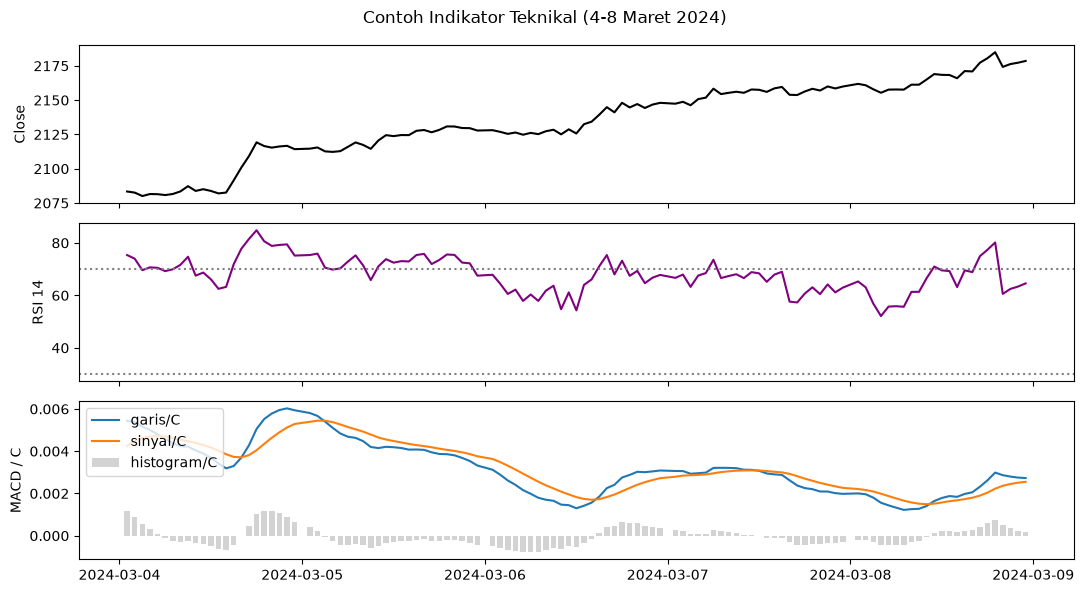

In [6]:
# Visualisasi contoh 1 minggu (4-8 Maret 2024)
minggu = df[(df["time"] >= "2024-03-04") & (df["time"] < "2024-03-09")].index

fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
ax[0].plot(df.loc[minggu, "time"], df.loc[minggu, "close"], color="black")
ax[0].set_ylabel("Close")

ax[1].plot(df.loc[minggu, "time"], fitur.loc[minggu, "rsi_14"], color="purple")
ax[1].axhline(70, ls=":", color="gray")
ax[1].axhline(30, ls=":", color="gray")
ax[1].set_ylabel("RSI 14")

ax[2].plot(df.loc[minggu, "time"], fitur.loc[minggu, "macd_line_norm"], label="garis/C")
ax[2].plot(df.loc[minggu, "time"], fitur.loc[minggu, "macd_signal_norm"], label="sinyal/C")
ax[2].bar(df.loc[minggu, "time"], fitur.loc[minggu, "macd_hist_norm"], width=0.03, color="lightgray", label="histogram/C")
ax[2].legend(loc="upper left")
ax[2].set_ylabel("MACD / C")

fig.suptitle("Contoh Indikator Teknikal (4-8 Maret 2024)")
plt.tight_layout()
plt.show()

In [7]:
fitur.insert(0, "time", df["time"])
fitur.to_parquet(f"{DATA_DIR}/03_fitur.parquet", index=False)
print("Selesai! Tersimpan:", f"{DATA_DIR}/03_fitur.parquet", fitur.shape)

Selesai! Tersimpan: ../data/interim/phase4-p0/03_fitur.parquet (38799, 16)
